ML Assignment -1

Dataset: Titanic Dataset (titanic_data_updated.csv)

Total Marks: 100

Email:shaswatabarua190@gmail.com


Name:Shaswata Barua

Exam Instructions :
- প্রথমে একটি Google Colab ফাইল খুলবে , এরপর প্রথম cell এ নিজের নাম এবং কোর্সে registration করা ইমেইল দিবে
- Question wise numbering করে Text cell রাখবে এবং এর নিচে Code cell থাকবে, চেষ্টা করবে একটি code cell এ একটি question উত্তর দেয়ার
- Google colab এর মধ্যে কোডগুলো করবে
- এবং সেই ফাইলটি ‘Anyone with the link’ & ‘View’ Access দিয়ে ফাইলটির Shareble Link টি সাবমিট করবে।


# Question 1 (10 Marks)
Load the Titanic dataset and display:
- Dataset shape
- First 10 rows
- 5 random samples

In [26]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer

df = pd.read_csv('/content/titanic_data_updated.csv')

print(df.shape)
print(df.head(10))
print(df.sample(5,random_state=42))

(891, 12)
   PassengerId Survived  Pclass  \
0            1       no   third   
1            2      yes   first   
2            3      yes   third   
3            4      yes   first   
4            5       no   third   
5            6       no   third   
6            7       no   first   
7            8       no   third   
8            9      yes   third   
9           10      yes  second   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   
5                                   Moran, Mr. James    male   NaN      0   
6                            McCarthy, Mr. Timothy J    male  54.

# Question 2 (10 Marks)
Perform feature screening on the Titanic dataset by:
- Finding total missing values
- Finding duplicate rows
- Removing duplicate rows permanently

In [27]:
print(df.isnull().sum())
print(df.duplicated())
print(df.duplicated().sum())
df.drop_duplicates(inplace=True)

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64
0      False
1      False
2      False
3      False
4      False
       ...  
886    False
887    False
888    False
889    False
890    False
Length: 891, dtype: bool
0


# Question 3 (10 Marks)
Perform statistical profiling of the Titanic dataset and display:
- Dataset information
- Statistical summary of numerical columns

Also write 2 observations from the output.


In [28]:
print(df.info())
print(df.describe())

#Cabin is missing for most passengers ,
# Age has 177 missing entries, and Embarked has 2.

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    object 
 2   Pclass       891 non-null    object 
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(3), object(7)
memory usage: 83.7+ KB
None
       PassengerId         Age       SibSp       Parch        Fare
count   891.000000  714.000000  891.000000  891.000000  891.000000
mean    446.000000   29.699118    0.523008    0.381594   32.204208
std     257.353842   14.526497    1.10

# Question 4 (10 Marks)
Perform univariate categorical analysis on the Survived column by:
- Creating a countplot
- Calculating percentage distribution
- Creating a pie chart

Write 2 insights from the analysis.

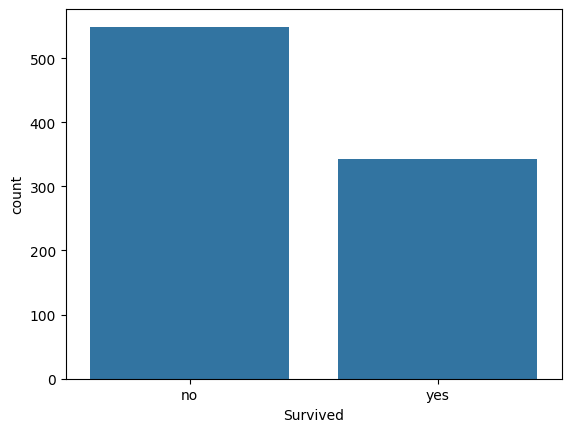

Survived
no     61.616162
yes    38.383838
Name: count, dtype: float64


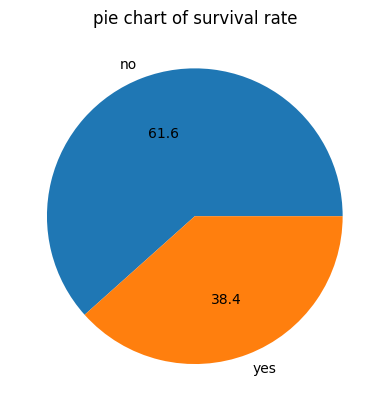

In [29]:
sns.countplot(data = df , x=df['Survived'])
plt.show()
print((df['Survived'].value_counts() / len(df) ) * 100)

survived_count =  df['Survived'].value_counts()

survived_label = df['Survived'].unique()

plt.pie(survived_count, labels = survived_label, autopct="%1.1f")
plt.title('pie chart of survival rate')
plt.show()

#Most passengers in the dataset did not survive only 61.6% did.

# The class data in survival is imbalance so if we train data it wont be accurate.

# Question 5 (10 Marks)
Perform univariate numerical analysis on the Age column by:
- Creating a histogram
- Creating a KDE plot

Write 2 observations from the plots.


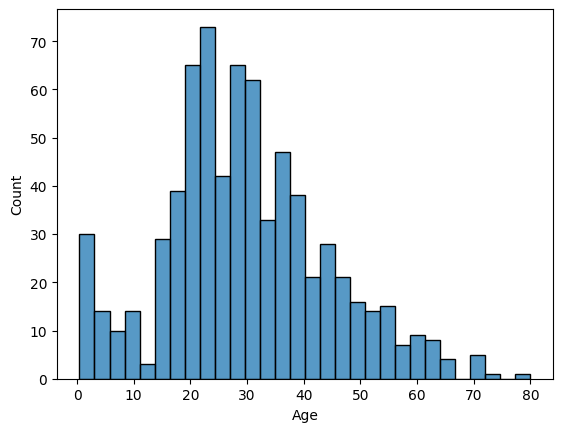

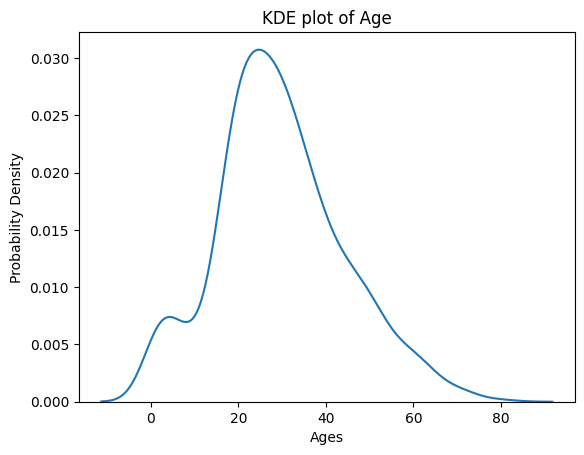

In [30]:
sns.histplot(df['Age'],bins = 30)
plt.show()
sns.kdeplot(df['Age'])
plt.title('KDE plot of Age')
plt.xlabel('Ages')
plt.ylabel('Probability Density')

plt.show()

#We can see that most of the passenger are 20-30 ages.
# In kde plot there are a infant spike so it is right skewed

# Question 6 (10 Marks)
Perform multivariate analysis between Sex and Survived using a countplot with hue.

Also calculate normalized survival ratios using groupby().

Write 2 insights from the analysis.


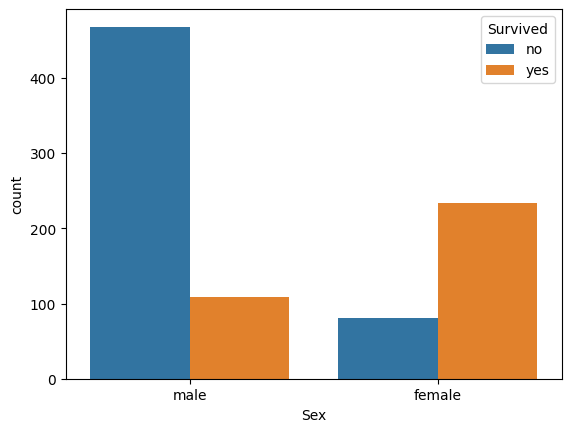

Sex     Survived
female  yes         0.742038
        no          0.257962
male    no          0.811092
        yes         0.188908
Name: proportion, dtype: float64


In [33]:
sns.countplot(x=df['Sex'],hue=df['Survived'])
plt.show()

gender_split = df.groupby('Sex')['Survived'].value_counts(normalize=True)

print(gender_split)

# Though male is bigger but female survival rates are way higher than male.
# Gender also is a key value for survival in this dataset

# Question 7 (10 Marks)

Create a barplot showing the relationship between Pclass and Fare.

Write 2 observations from the visualization.


<Axes: xlabel='Pclass', ylabel='Fare'>

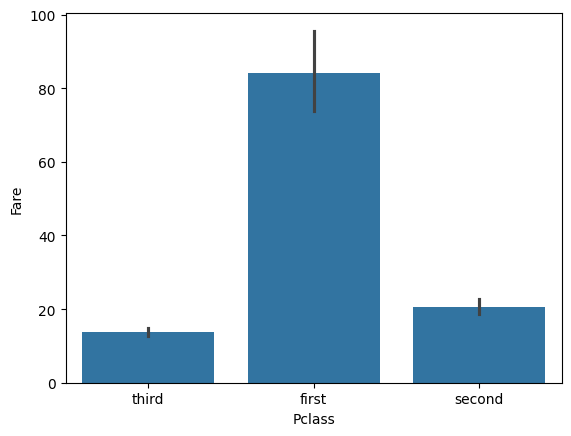

In [35]:
sns.barplot(x=df['Pclass'],y=df['Fare'])

#First class pay much more than third and second
# Since fare has much bigger numbers than pclass we should scale the data because it will be biased towards firts class

# Question 8 (10 Marks)

Create a KDE plot to compare the Age distribution of survived and non-survived passengers.

Write 2 insights from the graph.


<Axes: xlabel='Age', ylabel='Density'>

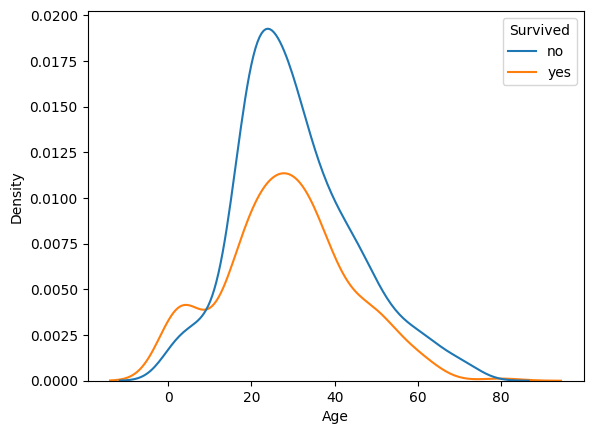

In [39]:
sns.kdeplot(data=df,x='Age',hue='Survived')

#Young childern has more survival rate as we can see from the right peak curve.
#Most died in between 20-35 ages.

# Question 9 (10 Marks)
Perform feature engineering and train-test split by:
- Dropping PassengerId, Name, and Ticket columns
- Separating features (X) and target (y)
- Splitting the dataset using test_size=0.2 and random_state=42

Display the shapes of train and test datasets.


In [40]:
df.drop(['Ticket','Name','PassengerId'],axis=1,inplace = True)
x = df.drop('Survived', axis=1)
y = df['Survived']
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

print(x_train.shape,x_test.shape)
print(y_train.shape,y_test.shape)

(712, 8) (179, 8)
(712,) (179,)


# Question 10 (10 Marks)
Handle missing values in the Titanic dataset by:
- Imputing missing Age values using SimpleImputer with mean strategy
- Imputing missing Embarked values using most frequent strategy
- Imputing missing Cabin values using constant strategy with "Missing"

Finally, check whether any missing values remain.


In [41]:
age_imputer = SimpleImputer(missing_values=np.nan , strategy='mean')

age_imputer.fit(x_train[['Age']])

x_train['Age'] = age_imputer.transform(x_train[['Age']]).ravel()

x_test['Age'] = age_imputer.transform(x_test[['Age']]).ravel()

Embarked_imputor = SimpleImputer(missing_values= np.nan, strategy ='most_frequent')


Embarked_imputor.fit(x_train[['Embarked']])



x_train['Embarked']=Embarked_imputor.transform(x_train[['Embarked']]).ravel()

x_test['Embarked']=Embarked_imputor.transform(x_test[['Embarked']]).ravel()

cabin_imputor = SimpleImputer(missing_values= np.nan, strategy ='constant',fill_value='Missing',add_indicator=True)


cabin_imputor.fit(x_train[['Cabin']])


x_train[['Cabin','cabin_missing_indicator']]=cabin_imputor.transform(x_train[['Cabin']])

x_test[['Cabin','cabin_missing_indicator']]=cabin_imputor.transform(x_test[['Cabin']])

print(x_train.isnull().sum())
print(x_test.isnull().sum())

Pclass                     0
Sex                        0
Age                        0
SibSp                      0
Parch                      0
Fare                       0
Cabin                      0
Embarked                   0
cabin_missing_indicator    0
dtype: int64
Pclass                     0
Sex                        0
Age                        0
SibSp                      0
Parch                      0
Fare                       0
Cabin                      0
Embarked                   0
cabin_missing_indicator    0
dtype: int64
